In [1]:
# Paths del proyecto: centralizados en src/config.py
import sys
from pathlib import Path

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

# Experimento: variables agroclimáticas nuevas

Prueba paralela. **No modifica ningún notebook ni el dataset de modelado**: lee los mismos archivos que el 03 y el 04, calcula variables nuevas en memoria y compara contra el modelo actual con la misma validación (Random Forest, walk-forward 2016–2024).

Cada grupo de variables se prueba **por separado** sumado al modelo actual, para saber qué aporta cada uno. Una variable se considera útil solo si:

1. baja el MAE en la ventana oct_ene (la que se usa para anticipar),
2. la mejora aparece en la mayoría de las 9 campañas de test (no solo en 2022),
3. la mejora se sostiene con distintas semillas del Random Forest.

In [2]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Mismos archivos que usan los notebooks 03 y 04 (solo lectura)
df_base = pd.read_csv(DATA_PROCESSED / "dataset_modelado_soja.csv")
df_clima = pd.read_csv(DATA_RAW / "nasa_power" / "nasa_power_zona_coop_1999_2025.csv", parse_dates=["fecha"])
df_ndvi = pd.read_csv(DATA_RAW / "ndvi" / "ndvi_modis_zona_coop_2000_2025.csv", parse_dates=["fecha"])

META_COLS = ["campana", "partido", "rinde_qq_ha", "superficie_sembrada_ha", "superficie_cosechada_ha"]
VENTANAS = {"oct_nov": (10, 11), "oct_dic": (10, 12), "oct_ene": (10, 13), "oct_feb": (10, 14), "oct_mar": (10, 15)}
PARTIDOS = sorted(df_base["partido"].unique())
PRIMER_TEST = 2016
RF_PARAMS = {"n_estimators": 100, "max_depth": 5}   # mismos que el 04
SEMILLAS = [42, 0, 1, 2, 3]                          # 42 = la del 04

def mes_campana(fecha, campana):
    """Igual que en el notebook 03: oct=10 ... ene=13, feb=14, mar=15."""
    if fecha.year == campana:
        return fecha.month
    elif fecha.year == campana + 1:
        return fecha.month + 12
    return None

print(f"Dataset actual: {df_base.shape}  |  Clima: {df_clima.shape}  |  NDVI: {df_ndvi.shape}")

Dataset actual: (125, 70)  |  Clima: (46870, 11)  |  NDVI: (2900, 5)


## Variables nuevas y su justificación

| Grupo | Variables | Por qué puede mejorar la estimación |
|---|---|---|
| **VPD** | `vpd_media` | Déficit de presión de vapor: cuánto "tira" la atmósfera del agua de la planta. Combina temperatura y humedad de forma no lineal; con VPD alto la soja cierra estomas y deja de fijar carbono. Se calcula con T2M_MAX, T2M_MIN y T2MDEW (ya descargado, no usado). |
| **Balance hídrico** | `balance_hidrico` | Lluvia menos evapotranspiración de referencia (Hargreaves, FAO-56). 300 mm con 25 °C no son lo mismo que 300 mm con 32 °C: el balance mide la oferta de agua *neta*, que es lo que define el rinde en secano. |
| **Distribución de lluvias** | `racha_seca_max`, `precip_cv` | El acumulado no distingue lluvias repartidas de pocas tormentas. La racha seca más larga capta los "baches" de agua que más daño hacen. |
| **Lluvia pre-siembra** | `precip_presiembra` | Lluvia de julio a septiembre: recarga del perfil del suelo antes de sembrar. En el noroeste bonaerense un perfil cargado amortigua una primavera seca. Hoy el modelo arranca a mirar en octubre. |
| **Último mes** | `precip_ultmes`, `tmax_ultmes`, `vpd_ultmes` | Las ventanas son acumuladas desde octubre, entonces lo que pasó en enero queda diluido en el promedio de cuatro meses. Enero es el inicio del período crítico (floración - inicio de llenado). |
| **Anomalía de NDVI** | `ndvi_anom_media`, `ndvi_anom_ultimo` | NDVI comparado con lo normal de ese partido en esa fecha. Saca de encima la diferencia estructural entre partidos (uso del suelo, lagunas) y deja la señal de "este año viene mejor o peor". La referencia "normal" se calcula solo con 2000–2015 para no filtrar información del período de test. |
| **Tendencia tecnológica** | (no es variable: cambia el target) | El rinde sube con los años por genética y manejo. El Random Forest no puede proyectar tendencias. Se prueba quitar una tendencia lineal ajustada solo con años de entrenamiento, modelar el desvío y volver a sumarla. |

Descarté **grados-día (GDD)** aunque lo había sugerido: con ventanas de calendario fijas y temperaturas medias que casi nunca bajan de 10 °C entre octubre y marzo, el GDD es prácticamente `(temp_media − 10) × días`, o sea la misma información que `temp_media`, que el modelo ya tiene. Un árbol de decisión no gana nada con eso.

In [3]:
def presion_vapor(t):
    """Presión de vapor de saturación (kPa), FAO-56 ec. 11."""
    return 0.6108 * np.exp(17.27 * t / (t + 237.3))

def radiacion_extraterrestre(lat_grados, dia_juliano):
    """Ra (MJ/m²/día), FAO-56 ec. 21."""
    phi = np.radians(lat_grados)
    dr = 1 + 0.033 * np.cos(2 * np.pi * dia_juliano / 365)
    delta = 0.409 * np.sin(2 * np.pi * dia_juliano / 365 - 1.39)
    ws = np.arccos(np.clip(-np.tan(phi) * np.tan(delta), -1, 1))
    return (24 * 60 / np.pi) * 0.0820 * dr * (ws * np.sin(phi) * np.sin(delta) + np.cos(phi) * np.cos(delta) * np.sin(ws))

# Variables diarias derivadas
dc = df_clima.copy()
dc["vpd"] = (presion_vapor(dc["T2M_MAX"]) + presion_vapor(dc["T2M_MIN"])) / 2 - presion_vapor(dc["T2MDEW"])
ra = radiacion_extraterrestre(dc["lat"], dc["fecha"].dt.dayofyear)
amplitud = (dc["T2M_MAX"] - dc["T2M_MIN"]).clip(lower=0)
dc["et0"] = 0.0023 * (dc["T2M"] + 17.8) * np.sqrt(amplitud) * 0.408 * ra   # Hargreaves (mm/día)

def racha_maxima(seco):
    """Máxima cantidad de días consecutivos en True."""
    maxima = actual = 0
    for s in seco:
        actual = actual + 1 if s else 0
        maxima = max(maxima, actual)
    return maxima

filas = []
for campana in range(2000, 2025):
    inicio, fin = pd.Timestamp(f"{campana}-09-01"), pd.Timestamp(f"{campana+1}-05-31")
    d = dc[(dc["fecha"] >= inicio) & (dc["fecha"] <= fin)].copy()
    d["mes_camp"] = d["fecha"].apply(lambda f: mes_campana(f, campana))
    pre = dc[(dc["fecha"] >= f"{campana}-07-01") & (dc["fecha"] <= f"{campana}-09-30")]

    for partido in PARTIDOS:
        dp = d[d["partido"] == partido].sort_values("fecha")
        if len(dp) == 0:
            continue
        row = {"campana": campana, "partido": partido,
               "precip_presiembra": pre.loc[pre["partido"] == partido, "PRECTOTCORR"].sum()}

        for v, (m_ini, m_fin) in VENTANAS.items():
            dv = dp[(dp["mes_camp"] >= m_ini) & (dp["mes_camp"] <= m_fin)]
            ult = dp[dp["mes_camp"] == m_fin]
            if len(dv) == 0:
                continue
            p = dv["PRECTOTCORR"]
            row[f"vpd_media_{v}"] = dv["vpd"].mean()
            row[f"balance_hidrico_{v}"] = p.sum() - dv["et0"].sum()
            row[f"racha_seca_max_{v}"] = racha_maxima((p < 1).values)
            row[f"precip_cv_{v}"] = p.std() / p.mean() if p.mean() > 0 else np.nan
            row[f"precip_ultmes_{v}"] = ult["PRECTOTCORR"].sum()
            row[f"tmax_ultmes_{v}"] = ult["T2M_MAX"].mean()
            row[f"vpd_ultmes_{v}"] = ult["vpd"].mean()
        filas.append(row)

df_clima_nuevas = pd.DataFrame(filas)
print(f"Variables climáticas nuevas: {df_clima_nuevas.shape[1] - 2}")
df_clima_nuevas.describe().T[["mean", "min", "max"]].round(2).head(9)

Variables climáticas nuevas: 36


,mean,min,max
campana,2012.00,2000.00,2024.00
precip_presiembra,138.67,20.69,437.15
vpd_media_oct_nov,1.02,0.56,1.63
balance_hidrico_oct_nov,-64.24,-220.54,185.34
racha_seca_max_oct_nov,10.25,4.00,19.00
precip_cv_oct_nov,2.41,1.48,4.03
precip_ultmes_oct_nov,113.06,12.49,222.84
tmax_ultmes_oct_nov,27.04,23.31,32.53
vpd_ultmes_oct_nov,1.18,0.69,2.11


In [4]:
# Anomalía de NDVI: desvío respecto de lo normal para ese partido en esa fecha del año.
# "Normal" = promedio 2000-2015 (años que están en el entrenamiento de todos los cortes del walk-forward).
dn = df_ndvi.copy()
dn["doy"] = dn["fecha"].dt.dayofyear
dn["campana_ref"] = np.where(dn["fecha"].dt.month >= 9, dn["fecha"].dt.year, dn["fecha"].dt.year - 1)
clim = (dn[dn["campana_ref"] < PRIMER_TEST]
        .groupby(["partido", "doy"])["ndvi"].mean().rename("ndvi_normal").reset_index())
dn = dn.merge(clim, on=["partido", "doy"], how="left")
dn["ndvi_anom"] = dn["ndvi"] - dn["ndvi_normal"]

filas = []
for campana in range(2000, 2025):
    d = dn[(dn["fecha"] >= f"{campana}-09-01") & (dn["fecha"] <= f"{campana+1}-05-31")].copy()
    d["mes_camp"] = d["fecha"].apply(lambda f: mes_campana(f, campana))
    for partido in PARTIDOS:
        dp = d[d["partido"] == partido].sort_values("fecha")
        if len(dp) == 0:
            continue
        row = {"campana": campana, "partido": partido}
        for v, (m_ini, m_fin) in VENTANAS.items():
            dv = dp[(dp["mes_camp"] >= m_ini) & (dp["mes_camp"] <= m_fin)].dropna(subset=["ndvi_anom"])
            if len(dv) == 0:
                continue
            row[f"ndvi_anom_media_{v}"] = dv["ndvi_anom"].mean()
            row[f"ndvi_anom_ultimo_{v}"] = dv["ndvi_anom"].iloc[-1]   # estado del cultivo a la fecha de corte
        filas.append(row)

df_ndvi_nuevas = pd.DataFrame(filas)
print(f"Variables NDVI nuevas: {df_ndvi_nuevas.shape[1] - 2}")

Variables NDVI nuevas: 10


In [5]:
df = (df_base
      .merge(df_clima_nuevas, on=["campana", "partido"], how="left")
      .merge(df_ndvi_nuevas, on=["campana", "partido"], how="left"))

assert len(df) == len(df_base), "El merge cambió la cantidad de filas"
assert df[df_base.columns].equals(df_base), "Las columnas originales cambiaron"
nulos = df.isnull().sum()
print(f"Filas: {len(df)}  |  Columnas originales: {df_base.shape[1]}  |  Columnas con nuevas: {df.shape[1]}")
print("Nulos en variables nuevas:", nulos[nulos > 0].to_dict() if nulos.sum() else "ninguno")

Filas: 125  |  Columnas originales: 70  |  Columnas con nuevas: 116
Nulos en variables nuevas: ninguno


## Diseño de la comparación

- **Misma validación que el 04**: entrena con 2000–2015, predice 2016, agrega 2016 al entrenamiento, predice 2017, y así hasta 2024 (45 predicciones).
- **Mismas variables base**: las del 04 para cada ventana. A eso se le suma un grupo nuevo por vez.
- **5 semillas del Random Forest** promediadas: con 45 predicciones, cambiar la semilla puede mover el MAE unas décimas. Si una mejora no supera ese ruido, no es mejora.
- **Intervalo de la diferencia (bootstrap por campaña)**: se re-sortean las 9 campañas de test 2.000 veces y se mira cuánto varía la diferencia de MAE. Se sortean campañas enteras porque los 5 partidos de una misma campaña se equivocan juntos.
- **Sin 2022**: la diferencia de MAE excluyendo la sequía, para ver si la mejora es general o depende de un solo año.

In [6]:
GRUPOS = {
    "VPD": ["vpd_media"],
    "Balance hídrico": ["balance_hidrico"],
    "Distribución lluvias": ["racha_seca_max", "precip_cv"],
    "Lluvia pre-siembra": ["precip_presiembra"],
    "Último mes": ["precip_ultmes", "tmax_ultmes", "vpd_ultmes"],
    "Anomalía NDVI": ["ndvi_anom_media", "ndvi_anom_ultimo"],
}
NOMBRES_V = list(VENTANAS)

def features_base(ventana):
    """Exactamente las mismas que get_features_ventana() del notebook 04."""
    disp = NOMBRES_V[:NOMBRES_V.index(ventana) + 1]
    return [c for c in df_base.columns if c not in META_COLS and any(c.endswith(v) for v in disp)]

def features_grupo(prefijos, ventana):
    disp = NOMBRES_V[:NOMBRES_V.index(ventana) + 1]
    cols = []
    for p in prefijos:
        cols += [p] if p in df.columns else [f"{p}_{v}" for v in disp if f"{p}_{v}" in df.columns]
    return cols

def walk_forward(features, semilla, tendencia=False):
    out = []
    for t in range(PRIMER_TEST, 2025):
        tr, te = df[df["campana"] < t], df[df["campana"] == t]
        if len(te) == 0:
            continue
        y_tr = tr["rinde_qq_ha"].values
        if tendencia:  # tendencia lineal ajustada SOLO con años de entrenamiento
            lr = LinearRegression().fit(tr[["campana"]], y_tr)
            tend_tr, tend_te = lr.predict(tr[["campana"]]), lr.predict(te[["campana"]])
        else:
            tend_tr, tend_te = 0, 0
        sc = StandardScaler()
        rf = RandomForestRegressor(**RF_PARAMS, random_state=semilla)
        rf.fit(sc.fit_transform(tr[features]), y_tr - tend_tr)
        pred = rf.predict(sc.transform(te[features])) + tend_te
        media_hist = tr.groupby("partido")["rinde_qq_ha"].mean()
        out.append(pd.DataFrame({"campana": t, "partido": te["partido"].values,
                                 "real": te["rinde_qq_ha"].values, "pred": pred,
                                 "media_hist": te["partido"].map(media_hist).values}))
    return pd.concat(out, ignore_index=True)

def correr(features, tendencia=False):
    """Promedia las predicciones de las 5 semillas; devuelve también el MAE de cada semilla."""
    corridas = [walk_forward(features, s, tendencia) for s in SEMILLAS]
    res = corridas[0].copy()
    res["pred"] = np.mean([c["pred"] for c in corridas], axis=0)
    mae_semillas = [mean_absolute_error(c["real"], c["pred"]) for c in corridas]
    return res, mae_semillas

# Tarda unos 3-5 minutos: 8 variantes × 5 ventanas × 5 semillas × 9 campañas
variantes = {"Modelo actual": ([], False)}
variantes.update({f"+ {g}": (p, False) for g, p in GRUPOS.items()})
variantes["+ Tendencia tecnológica"] = ([], True)

resultados = {}
for nombre, (prefijos, tend) in variantes.items():
    print(f"Corriendo {nombre}...", flush=True)
    for v in NOMBRES_V:
        feats = features_base(v) + features_grupo(prefijos, v)
        resultados[(nombre, v)] = correr(feats, tend) + (len(feats),)
print("Listo.")

Corriendo Modelo actual...
Corriendo + VPD...
Corriendo + Balance hídrico...
Corriendo + Distribución lluvias...
Corriendo + Lluvia pre-siembra...
Corriendo + Último mes...
Corriendo + Anomalía NDVI...
Corriendo + Tendencia tecnológica...
Listo.


In [7]:
# Control: con la semilla 42 el modelo actual tiene que dar lo mismo que el notebook 04
control = walk_forward(features_base("oct_ene"), 42)
print(f"Control: MAE modelo actual oct_ene, semilla 42 = {mean_absolute_error(control['real'], control['pred']):.2f} qq/ha")
print("Tiene que coincidir con el MAE de Random Forest oct_ene del notebook 04. Si no coincide, algo cambió en los datos.")

Control: MAE modelo actual oct_ene, semilla 42 = 3.27 qq/ha
Tiene que coincidir con el MAE de Random Forest oct_ene del notebook 04. Si no coincide, algo cambió en los datos.


In [8]:
rng = np.random.default_rng(0)
CAMPANAS_TEST = list(range(PRIMER_TEST, 2025))

def comparar(base, nueva):
    e_b = (base["real"] - base["pred"]).abs()
    e_n = (nueva["real"] - nueva["pred"]).abs()
    por_camp = pd.DataFrame({"c": base["campana"], "d": e_n - e_b}).groupby("c")["d"].mean()
    boot = [por_camp.loc[rng.choice(CAMPANAS_TEST, len(CAMPANAS_TEST))].mean() for _ in range(2000)]
    sin22 = base["campana"] != 2022
    return {
        "dMAE": e_n.mean() - e_b.mean(),
        "IC80_inf": np.percentile(boot, 10), "IC80_sup": np.percentile(boot, 90),
        "campanas_mejoran": int((por_camp < 0).sum()),
        "dMAE_sin_2022": e_n[sin22].mean() - e_b[sin22].mean(),
    }

def acierto_direccional(r):
    return (np.sign(r["pred"] - r["media_hist"]) == np.sign(r["real"] - r["media_hist"])).mean()

filas = []
for (nombre, v), (res, mae_sem, nf) in resultados.items():
    fila = {"variante": nombre, "ventana": v, "n_features": nf,
            "MAE": mean_absolute_error(res["real"], res["pred"]),
            "MAE_rango_semillas": max(mae_sem) - min(mae_sem),
            "acierto_dir": acierto_direccional(res)}
    fila.update(comparar(resultados[("Modelo actual", v)][0], res))
    filas.append(fila)
tabla = pd.DataFrame(filas)

ene = tabla[tabla["ventana"] == "oct_ene"].set_index("variante")
print("VENTANA OCT_ENE (la que se usa para anticipar) — promedio de 5 semillas")
print("=" * 104)
print(f"{'Variante':28s}| {'MAE':>5s} | {'ΔMAE':>6s} | {'IC 80% de ΔMAE':>16s} | {'Mejora en':>9s} | {'ΔMAE s/2022':>11s} | {'Acierto dir.':>12s}")
print("-" * 104)
for n, r in ene.iterrows():
    ic = "" if n == "Modelo actual" else f"[{r.IC80_inf:+.2f}, {r.IC80_sup:+.2f}]"
    mej = "" if n == "Modelo actual" else f"{r.campanas_mejoran}/9"
    print(f"{n:28s}| {r.MAE:5.2f} | {r.dMAE:+6.2f} | {ic:>16s} | {mej:>9s} | {r.dMAE_sin_2022:+11.2f} | {r.acierto_dir:11.0%}")
ruido = tabla.loc[(tabla.variante == "Modelo actual") & (tabla.ventana == "oct_ene"), "MAE_rango_semillas"].iloc[0]
print(f"\nRuido por semilla del modelo actual (máx − mín MAE entre 5 semillas): {ruido:.2f} qq/ha")
print("ΔMAE negativo = la variable baja el error. Si el IC 80% cruza el cero, la mejora no es concluyente.")

VENTANA OCT_ENE (la que se usa para anticipar) — promedio de 5 semillas
Variante                    |   MAE |   ΔMAE |   IC 80% de ΔMAE | Mejora en | ΔMAE s/2022 | Acierto dir.
--------------------------------------------------------------------------------------------------------
Modelo actual               |  3.10 |  +0.00 |                  |           |       +0.00 |         71%
+ VPD                       |  2.97 |  -0.13 |   [-0.27, -0.01] |       7/9 |       -0.05 |         71%
+ Balance hídrico           |  3.06 |  -0.04 |   [-0.07, -0.00] |       8/9 |       -0.02 |         71%
+ Distribución lluvias      |  3.18 |  +0.08 |   [+0.05, +0.11] |       1/9 |       +0.07 |         71%
+ Lluvia pre-siembra        |  3.09 |  -0.01 |   [-0.05, +0.03] |       5/9 |       -0.02 |         73%
+ Último mes                |  3.09 |  -0.01 |   [-0.08, +0.06] |       4/9 |       -0.04 |         71%
+ Anomalía NDVI             |  3.06 |  -0.04 |   [-0.21, +0.12] |       6/9 |       +0.06 |   

In [9]:
# ΔMAE por ventana: ¿la mejora se mantiene a lo largo del ciclo o es de una sola ventana?
piv = tabla[tabla.variante != "Modelo actual"].pivot(index="variante", columns="ventana", values="dMAE")[NOMBRES_V]
print("ΔMAE vs modelo actual por ventana (negativo = mejora)")
print(piv.round(2).to_string())

ΔMAE vs modelo actual por ventana (negativo = mejora)
ventana                  oct_nov  oct_dic  oct_ene  oct_feb  oct_mar
variante                                                            
+ Anomalía NDVI            -0.89    -0.66    -0.04    -0.15    -0.04
+ Balance hídrico           0.07     0.09    -0.04    -0.02    -0.01
+ Distribución lluvias      0.04     0.08     0.08     0.06     0.10
+ Lluvia pre-siembra        0.10     0.01    -0.01    -0.02    -0.01
+ Tendencia tecnológica     1.20     1.28     1.46     0.97     1.08
+ VPD                      -0.18    -0.13    -0.13    -0.10    -0.00
+ Último mes               -0.39    -0.07    -0.01    -0.18    -0.13


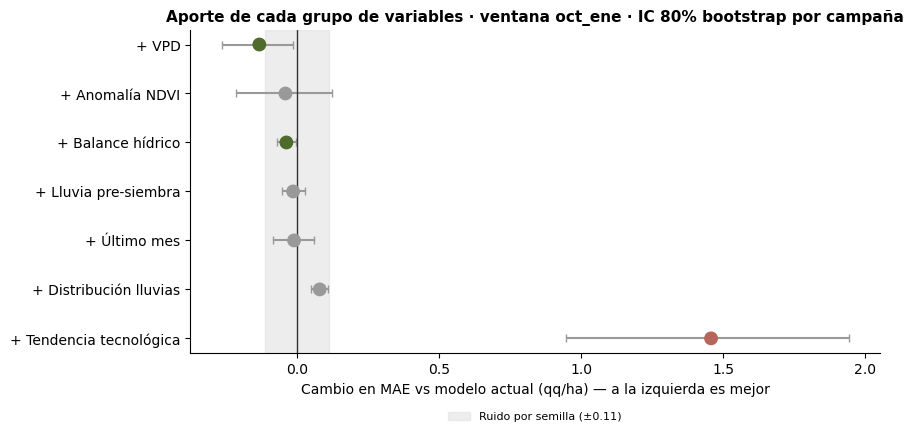

In [10]:
d = ene.drop("Modelo actual").sort_values("dMAE", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(d))
def color(r):
    if r.IC80_sup < 0: return "#4E6B2C"            # mejora concluyente
    if abs(r.dMAE) <= ruido / 2: return "#999999"   # dentro del ruido: sin efecto
    return "#9AA58A" if r.dMAE < 0 else "#B5655A"   # mejora dudosa / empeora
colores = [color(r) for _, r in d.iterrows()]
ax.errorbar(d["dMAE"], y, xerr=[d["dMAE"] - d["IC80_inf"], d["IC80_sup"] - d["dMAE"]],
            fmt="none", ecolor="#999", elinewidth=1.5, capsize=3)
ax.scatter(d["dMAE"], y, c=colores, s=80, zorder=3)
ax.axvline(0, color="#333", lw=1)
ax.axvspan(-ruido / 2, ruido / 2, color="#ddd", alpha=0.5, label=f"Ruido por semilla (±{ruido/2:.2f})")
ax.set_yticks(y); ax.set_yticklabels(d.index)
ax.set_xlabel("Cambio en MAE vs modelo actual (qq/ha) — a la izquierda es mejor")
ax.set_title("Aporte de cada grupo de variables · ventana oct_ene · IC 80% bootstrap por campaña", fontsize=11, fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUTPUTS / "experimento_features_nuevas.png", dpi=150, bbox_inches="tight")
plt.show()

## Combinación de los grupos que aportan

Se suman juntos solo los grupos que cumplieron el criterio en oct_ene: bajan el MAE, mejoran al menos 5 de las 9 campañas y la mejora sigue sin 2022.

**Ojo:** esta combinación se eligió mirando el mismo período de test, así que su resultado es optimista. La prueba real es la campaña 2025/26 cuando MAGyP publique los rindes por departamento.

In [11]:
elegidos = [n for n, r in ene.drop("Modelo actual").iterrows()
            if r.dMAE < 0 and r.campanas_mejoran >= 5 and r.dMAE_sin_2022 < 0]
print("Grupos que cumplen el criterio:", elegidos if elegidos else "ninguno")

if elegidos:
    usar_tend = "+ Tendencia tecnológica" in elegidos
    prefijos = [p for n in elegidos if n != "+ Tendencia tecnológica" for p in GRUPOS[n[2:]]]
    print(f"\n{'Ventana':10s}| {'MAE actual':>10s} | {'MAE combinado':>13s} | {'ΔMAE':>6s} | {'IC 80%':>16s} | {'Mejora en':>9s}")
    print("-" * 78)
    comb = {}
    for v in NOMBRES_V:
        feats = features_base(v) + features_grupo(prefijos, v)
        res, _ = correr(feats, usar_tend)
        comb[v] = res
        c = comparar(resultados[("Modelo actual", v)][0], res)
        mae_b = mean_absolute_error(resultados[("Modelo actual", v)][0]["real"], resultados[("Modelo actual", v)][0]["pred"])
        print(f"{v:10s}| {mae_b:10.2f} | {mae_b + c['dMAE']:13.2f} | {c['dMAE']:+6.2f} | [{c['IC80_inf']:+.2f}, {c['IC80_sup']:+.2f}] | {c['campanas_mejoran']:>7d}/9")
else:
    print("Ninguna variable nueva mejora de forma consistente: el modelo actual se queda como está.")

Grupos que cumplen el criterio: ['+ VPD', '+ Balance hídrico', '+ Lluvia pre-siembra']

Ventana   | MAE actual | MAE combinado |   ΔMAE |           IC 80% | Mejora en
------------------------------------------------------------------------------
oct_nov   |       3.54 |          3.42 |  -0.12 | [-0.30, +0.04] |       3/9
oct_dic   |       3.35 |          3.20 |  -0.15 | [-0.31, +0.01] |       6/9
oct_ene   |       3.10 |          3.02 |  -0.08 | [-0.15, -0.02] |       5/9
oct_feb   |       3.14 |          3.03 |  -0.12 | [-0.20, -0.04] |       6/9
oct_mar   |       2.99 |          2.93 |  -0.06 | [-0.10, -0.02] |       7/9


In [12]:
tabla.round(3).to_csv(OUTPUTS / "experimento_features_nuevas.csv", index=False)
print("Guardado: outputs/experimento_features_nuevas.csv y outputs/experimento_features_nuevas.png")

Guardado: outputs/experimento_features_nuevas.csv y outputs/experimento_features_nuevas.png


## Cómo leer el resultado

- **Mejora real**: ΔMAE negativo, IC 80% que no cruza el cero, mejora en 6 o más campañas y también sin 2022. Esa variable vale la pena incorporarla al notebook 03.
- **Mejora dudosa**: ΔMAE negativo pero el IC cruza el cero o la mejora es más chica que el ruido por semilla. Con 9 campañas de test no alcanza para afirmarlo; no conviene sumarla.
- **Empeora**: ΔMAE positivo. Con 125 observaciones, cada variable extra que no aporta le agrega ruido al Random Forest. Que una variable con sentido agronómico no mejore no significa que no importe: puede ser que el modelo ya capte esa información por otra vía (por ejemplo, el VPD está muy ligado a la humedad relativa, que ya es la variable más importante).

Este notebook no cambia nada del pipeline. Si alguna variable resulta útil, el paso siguiente es sumarla al notebook 03 y volver a correr 03 → 04 → 05.

---
# Parte 2: confirmar VPD y anomalía de NDVI, y probar El Niño / La Niña

La parte 1 dejó dos candidatas:

- **VPD**: mejora chica pero consistente en oct_ene.
- **Anomalía de NDVI**: mejora fuerte en las ventanas tempranas (oct_nov, oct_dic), que el criterio de la parte 1 no miraba porque solo evaluaba oct_ene.

Acá se confirma cada una **en todas las ventanas** con el mismo rigor (IC 80%, campañas que mejoran, sin 2022) y se agregan dos pruebas nuevas:

1. **Control "identidad del partido"**: la anomalía de NDVI le resta a cada partido su NDVI normal. Si la mejora viene solo de eso (que el modelo "reconozca" qué partido es), darle directamente el nombre del partido tendría que mejorar lo mismo. Si la anomalía mejora bastante más, entonces está captando lo que interesa: si el año viene más verde o más seco que lo normal.
2. **ENSO (El Niño / La Niña)**: índice ONI de NOAA.

In [13]:
def tabla_ventanas(nombres):
    """ΔMAE por ventana con IC 80%, campañas que mejoran y efecto sin 2022."""
    print(f"{'Variante':30s}| {'Ventana':8s}| {'MAE actual':>10s} | {'MAE nuevo':>9s} | {'ΔMAE':>6s} | {'IC 80%':>16s} | {'Mejora en':>9s} | {'ΔMAE s/2022':>11s}")
    print("-" * 116)
    for n in nombres:
        for v in NOMBRES_V:
            base = resultados[("Modelo actual", v)][0]
            c = comparar(base, resultados[(n, v)][0])
            mae_b = mean_absolute_error(base["real"], base["pred"])
            marca = "  ✔" if (c["IC80_sup"] < 0 and c["campanas_mejoran"] >= 6 and c["dMAE_sin_2022"] < 0) else ""
            print(f"{n:30s}| {v:8s}| {mae_b:10.2f} | {mae_b + c['dMAE']:9.2f} | {c['dMAE']:+6.2f} | "
                  f"[{c['IC80_inf']:+.2f}, {c['IC80_sup']:+.2f}] | {c['campanas_mejoran']:>7d}/9 | {c['dMAE_sin_2022']:+11.2f}{marca}")
        print("-" * 116)
    print("✔ = mejora concluyente: IC 80% enteramente por debajo de cero, mejora en 6+ campañas y también sin 2022.")

tabla_ventanas(["+ VPD", "+ Anomalía NDVI"])

Variante                      | Ventana | MAE actual | MAE nuevo |   ΔMAE |           IC 80% | Mejora en | ΔMAE s/2022
--------------------------------------------------------------------------------------------------------------------
+ VPD                         | oct_nov |       3.54 |      3.36 |  -0.18 | [-0.31, -0.06] |       5/9 |       -0.15
+ VPD                         | oct_dic |       3.35 |      3.22 |  -0.13 | [-0.37, +0.09] |       5/9 |       -0.05
+ VPD                         | oct_ene |       3.10 |      2.97 |  -0.13 | [-0.26, -0.01] |       7/9 |       -0.05  ✔
+ VPD                         | oct_feb |       3.14 |      3.05 |  -0.10 | [-0.17, -0.02] |       5/9 |       -0.06
+ VPD                         | oct_mar |       2.99 |      2.99 |  -0.00 | [-0.02, +0.02] |       5/9 |       +0.01
--------------------------------------------------------------------------------------------------------------------
+ Anomalía NDVI               | oct_nov |       3.54 |     

In [14]:
# Control: ¿la anomalía de NDVI mejora solo porque le dice al modelo qué partido es?
dummies = pd.get_dummies(df["partido"], prefix="partido", dtype=float)
for c in dummies.columns:
    df[c] = dummies[c]
GRUPOS["Identidad partido"] = list(dummies.columns)

nuevas = {
    "+ Identidad partido": GRUPOS["Identidad partido"],
    "+ VPD + Anomalía NDVI": GRUPOS["VPD"] + GRUPOS["Anomalía NDVI"],
}
for nombre, prefijos in nuevas.items():
    print(f"Corriendo {nombre}...", flush=True)
    for v in NOMBRES_V:
        feats = features_base(v) + features_grupo(prefijos, v)
        resultados[(nombre, v)] = correr(feats) + (len(feats),)

print()
tabla_ventanas(["+ Identidad partido", "+ VPD + Anomalía NDVI"])

Corriendo + Identidad partido...
Corriendo + VPD + Anomalía NDVI...

Variante                      | Ventana | MAE actual | MAE nuevo |   ΔMAE |           IC 80% | Mejora en | ΔMAE s/2022
--------------------------------------------------------------------------------------------------------------------
+ Identidad partido           | oct_nov |       3.54 |      3.50 |  -0.04 | [-0.10, +0.02] |       5/9 |       -0.04
+ Identidad partido           | oct_dic |       3.35 |      3.30 |  -0.05 | [-0.11, +0.00] |       5/9 |       -0.05
+ Identidad partido           | oct_ene |       3.10 |      3.12 |  +0.02 | [-0.02, +0.06] |       4/9 |       +0.04
+ Identidad partido           | oct_feb |       3.14 |      3.10 |  -0.05 | [-0.09, -0.00] |       5/9 |       -0.04
+ Identidad partido           | oct_mar |       2.99 |      3.02 |  +0.03 | [-0.02, +0.08] |       5/9 |       +0.00
--------------------------------------------------------------------------------------------------------------

In [15]:
# Detalle por campaña en las ventanas tempranas: ¿la anomalía mejora en general o en pocos años?
for v in ["oct_nov", "oct_dic"]:
    b = resultados[("Modelo actual", v)][0]
    a = resultados[("+ Anomalía NDVI", v)][0]
    det = pd.DataFrame({
        "campana": b["campana"],
        "error_actual": (b["real"] - b["pred"]).abs(),
        "error_con_anomalia": (a["real"] - a["pred"]).abs(),
    }).groupby("campana").mean()
    det["diferencia"] = det["error_con_anomalia"] - det["error_actual"]
    print(f"\n{v.upper()} — error medio de los 5 partidos por campaña (qq/ha)")
    print(det.round(2).to_string())


OCT_NOV — error medio de los 5 partidos por campaña (qq/ha)
         error_actual  error_con_anomalia  diferencia
campana                                              
2016             3.92                4.13        0.21
2017             4.97                4.09       -0.88
2018             1.97                1.93       -0.04
2019             2.00                1.74       -0.27
2020             2.60                2.99        0.39
2021             2.11                1.16       -0.95
2022             5.38                2.40       -2.98
2023             1.81                2.40        0.59
2024             7.07                2.95       -4.12

OCT_DIC — error medio de los 5 partidos por campaña (qq/ha)
         error_actual  error_con_anomalia  diferencia
campana                                              
2016             4.50                4.70        0.20
2017             5.22                5.02       -0.20
2018             1.86                1.80       -0.05
2019          

## El Niño / La Niña (ENSO)

Las variables climáticas del modelo ya "ven" el efecto de El Niño o La Niña, pero **recién cuando ocurre**: si La Niña trae una primavera seca, aparece como menos lluvia y más VPD a medida que pasan los meses.

Lo que el modelo no tiene es el **aviso previo**. El estado de ENSO se conoce antes de sembrar, y en la región pampeana El Niño se asocia a primaveras-veranos más lluviosos y La Niña a más secos (2022/23, la sequía, fue el tercer año seguido de La Niña). Esa información puede servir justamente en las ventanas tempranas, cuando todavía hay pocos datos de clima de la campaña.

**Variable:** ONI de agosto-septiembre-octubre (`oni_aso`), publicado por NOAA a principios de noviembre. Se usa el mismo valor en todas las ventanas, porque es lo que se conoce desde el principio de la campaña. Valores por encima de +0,5 indican Niño; por debajo de −0,5, Niña.

El archivo se descarga una vez de NOAA y se guarda en `data/raw/enso/` para las corridas siguientes.

In [16]:
ruta_oni = DATA_RAW / "enso" / "oni.csv"
if not ruta_oni.exists():
    url = "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"
    try:
        oni = pd.read_csv(url, sep=r"\s+")
        ruta_oni.parent.mkdir(parents=True, exist_ok=True)
        oni.to_csv(ruta_oni, index=False)
        print("ONI descargado de NOAA y guardado en", ruta_oni)
    except Exception as e:
        oni = None
        print("No se pudo descargar el ONI (¿sin internet?):", e)
else:
    oni = pd.read_csv(ruta_oni)
    print("ONI leído de", ruta_oni)

HAY_ENSO = oni is not None
if HAY_ENSO:
    oni_aso = oni[oni["SEAS"] == "ASO"].set_index("YR")["ANOM"]
    df["oni_aso"] = df["campana"].map(oni_aso)
    GRUPOS["ENSO"] = ["oni_aso"]
    resumen = df.groupby("campana").agg(rinde_zona=("rinde_qq_ha", "mean"), oni_aso=("oni_aso", "first"))
    resumen["fase"] = pd.cut(resumen["oni_aso"], [-9, -0.5, 0.5, 9], labels=["Niña", "Neutral", "Niño"])
    print("\nRinde medio de la zona según la fase de ENSO en la siembra (2000-2024):")
    print(resumen.groupby("fase", observed=True)["rinde_zona"].agg(["mean", "count"]).round(1)
          .rename(columns={"mean": "rinde medio qq/ha", "count": "campañas"}).to_string())
    print(f"\nCorrelación ONI (ago-oct) vs rinde de la zona: {resumen['oni_aso'].corr(resumen['rinde_zona']):+.2f}")
    ultimas = oni[oni["YR"] == oni["YR"].max()].tail(3)
    print("\nÚltimos valores publicados:", ", ".join(f"{s} {y}: {a:+.2f}" for s, y, a in ultimas[["SEAS", "YR", "ANOM"]].values))

ONI descargado de NOAA y guardado en C:\Users\agust\Documents\rinde-soja\data\raw\enso\oni.csv

Rinde medio de la zona según la fase de ENSO en la siembra (2000-2024):
         rinde medio qq/ha  campañas
fase                                
Niña                  28.8         6
Neutral               30.7        12
Niño                  33.9         7

Correlación ONI (ago-oct) vs rinde de la zona: +0.34

Últimos valores publicados: MJJ 2026: +1.39, JJA 2026: +1.80, JAS 2026: +2.16


In [17]:
if HAY_ENSO:
    nuevas = {
        "+ ENSO": GRUPOS["ENSO"],
        "+ VPD + Anomalía NDVI + ENSO": GRUPOS["VPD"] + GRUPOS["Anomalía NDVI"] + GRUPOS["ENSO"],
    }
    for nombre, prefijos in nuevas.items():
        print(f"Corriendo {nombre}...", flush=True)
        for v in NOMBRES_V:
            feats = features_base(v) + features_grupo(prefijos, v)
            resultados[(nombre, v)] = correr(feats) + (len(feats),)
    print()
    tabla_ventanas(list(nuevas))

Corriendo + ENSO...
Corriendo + VPD + Anomalía NDVI + ENSO...

Variante                      | Ventana | MAE actual | MAE nuevo |   ΔMAE |           IC 80% | Mejora en | ΔMAE s/2022
--------------------------------------------------------------------------------------------------------------------
+ ENSO                        | oct_nov |       3.54 |      3.61 |  +0.08 | [-0.04, +0.19] |       4/9 |       +0.09
+ ENSO                        | oct_dic |       3.35 |      3.34 |  -0.01 | [-0.10, +0.09] |       6/9 |       +0.02
+ ENSO                        | oct_ene |       3.10 |      3.09 |  -0.01 | [-0.06, +0.04] |       5/9 |       -0.00
+ ENSO                        | oct_feb |       3.14 |      3.14 |  +0.00 | [-0.02, +0.02] |       5/9 |       +0.00
+ ENSO                        | oct_mar |       2.99 |      2.97 |  -0.01 | [-0.06, +0.03] |       5/9 |       -0.01
--------------------------------------------------------------------------------------------------------------------

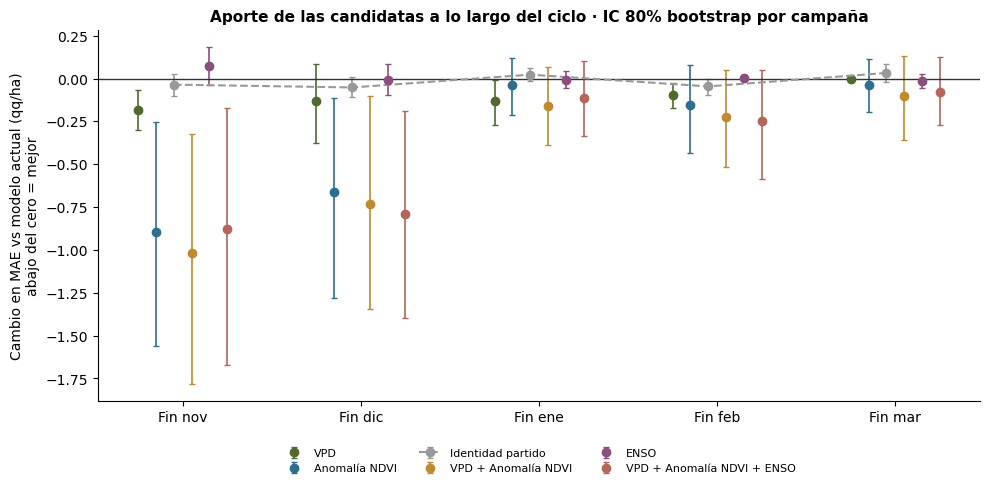

Guardado: outputs/experimento_parte2_candidatas.png y .csv


In [18]:
# Resumen visual: ¿cómo cambia el error a lo largo del ciclo con cada candidata?
candidatas = ["+ VPD", "+ Anomalía NDVI", "+ Identidad partido", "+ VPD + Anomalía NDVI"]
if HAY_ENSO:
    candidatas += ["+ ENSO", "+ VPD + Anomalía NDVI + ENSO"]
colores_c = ["#4E6B2C", "#2B6F8F", "#999999", "#C08A2E", "#8A4F7D", "#B5655A"]
etiquetas = ["Fin nov", "Fin dic", "Fin ene", "Fin feb", "Fin mar"]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(NOMBRES_V))
desp = np.linspace(-0.25, 0.25, len(candidatas))
filas_p2 = []
for k, (n, col) in enumerate(zip(candidatas, colores_c)):
    cs = [comparar(resultados[("Modelo actual", v)][0], resultados[(n, v)][0]) for v in NOMBRES_V]
    d_ = np.array([c["dMAE"] for c in cs])
    lo = np.array([c["IC80_inf"] for c in cs]); hi = np.array([c["IC80_sup"] for c in cs])
    ax.errorbar(x + desp[k], d_, yerr=[d_ - lo, hi - d_], fmt="o", color=col, ecolor=col,
                elinewidth=1.2, capsize=2, markersize=6, label=n[2:],
                linestyle="--" if n == "+ Identidad partido" else "none")
    for v, c in zip(NOMBRES_V, cs):
        filas_p2.append({"variante": n, "ventana": v, **c})
ax.axhline(0, color="#333", lw=1)
ax.set_xticks(x); ax.set_xticklabels(etiquetas)
ax.set_ylabel("Cambio en MAE vs modelo actual (qq/ha)\nabajo del cero = mejor")
ax.set_title("Aporte de las candidatas a lo largo del ciclo · IC 80% bootstrap por campaña", fontsize=11, fontweight="bold")
ax.legend(fontsize=8, frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUTPUTS / "experimento_parte2_candidatas.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(filas_p2).round(3).to_csv(OUTPUTS / "experimento_parte2_candidatas.csv", index=False)
print("Guardado: outputs/experimento_parte2_candidatas.png y .csv")

## Cómo leer la parte 2

- **✔ en la tabla**: la mejora es concluyente en esa ventana. Esa es la vara para sumar una variable al notebook 03.
- **Anomalía NDVI vs Identidad partido**: si la anomalía mejora claramente más que la identidad del partido, la señal es real ("el año viene más verde o más seco que lo normal"). Si mejoran parecido, la anomalía solo le estaba diciendo al modelo qué partido es.
- **ENSO**: lo esperable es que ayude sobre todo en fin de noviembre y diciembre, y que pierda peso después, cuando el clima observado ya refleja lo que hizo El Niño o La Niña. Con 25 campañas hay pocos años de cada fase, así que un resultado sin ✔ no descarta que ENSO importe; solo dice que con estos datos no alcanza para medirlo.
- Igual que en la parte 1: estas pruebas usan siempre las mismas 9 campañas de test. Cuantas más variantes se prueban, más chance de encontrar una mejora por casualidad. La confirmación definitiva es la campaña 2025/26 con los datos oficiales.

# PARTE 3 (a): datos de la campaña 2025/26 (clima NASA POWER + NDVI MODIS)

In [19]:
import requests, time
from config import PARTIDOS as COORDS
 
CAMPANA_PRUEBA = 2025
cols_nasa = ["T2M", "T2M_MAX", "T2M_MIN", "PRECTOTCORR", "ALLSKY_SFC_SW_DWN", "RH2M", "T2MDEW"]
 
clima_25 = []
for partido, c in COORDS.items():
    url = ("https://power.larc.nasa.gov/api/temporal/daily/point"
           f"?parameters={','.join(cols_nasa)}&community=AG&longitude={c['lon']}&latitude={c['lat']}"
           f"&start={CAMPANA_PRUEBA}0901&end={CAMPANA_PRUEBA+1}0430&format=JSON")
    dfp = pd.DataFrame(requests.get(url, timeout=120).json()["properties"]["parameter"])
    dfp = dfp.rename_axis("fecha").reset_index()
    dfp["fecha"] = pd.to_datetime(dfp["fecha"], format="%Y%m%d")
    dfp["partido"] = partido
    dfp[cols_nasa] = dfp[cols_nasa].replace(-999, np.nan)
    clima_25.append(dfp)
    print(f"Clima {partido}: {len(dfp)} días")
    time.sleep(2)
df_clima_25 = pd.concat(clima_25, ignore_index=True)
 
import ee
ee.Initialize(project="rinde-soja")
nombres_gaul = {"General Arenales": "General Arenales", "Leandro N. Alem": "Leandro N. Alem",
                "Junin": "Junín", "Lincoln": "Lincoln", "General Pinto": "General Pinto"}
fc = (ee.FeatureCollection("FAO/GAUL/2015/level2")
      .filter(ee.Filter.eq("ADM1_NAME", "Buenos Aires"))
      .filter(ee.Filter.inList("ADM2_NAME", list(nombres_gaul))))
modis = (ee.ImageCollection("MODIS/061/MOD13Q1")
         .filterDate(f"{CAMPANA_PRUEBA}-09-01", f"{CAMPANA_PRUEBA+1}-04-30").select("NDVI"))
feats = modis.map(lambda img: img.reduceRegions(collection=fc, reducer=ee.Reducer.mean(), scale=250)
                  .map(lambda f: f.set("fecha", img.date().format("YYYY-MM-dd")))).flatten().getInfo()
df_ndvi_25 = pd.DataFrame([{"fecha": f["properties"]["fecha"],
                            "partido": nombres_gaul[f["properties"]["ADM2_NAME"]],
                            "ndvi": f["properties"].get("mean", np.nan) * 0.0001} for f in feats["features"]])
df_ndvi_25["fecha"] = pd.to_datetime(df_ndvi_25["fecha"])
print(f"NDVI: {df_ndvi_25['fecha'].min().date()} a {df_ndvi_25['fecha'].max().date()}, {len(df_ndvi_25)} registros")

Clima General Arenales: 242 días
Clima Leandro N. Alem: 242 días
Clima Junín: 242 días
Clima Lincoln: 242 días
Clima General Pinto: 242 días


C:\Users\agust\AppData\Roaming\Python\Python312\site-packages\ee\deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


NDVI: 2025-09-14 a 2026-04-23, 75 registros


# PARTE 3 (b): comparar ambos modelos en la campaña 2025/26, mes a mes
# Los dos se entrenan con 2000-2024: la 2025/26 nunca la vieron.

CAMPAÑA 2025/26 — promedio de la zona (qq/ha) · promedio histórico 2000-2024: 31.1
Corte    | Modelo actual | vs hist. | VPD + anomalía | vs hist. | Diferencia
----------------------------------------------------------------------------------
Fin nov  |          31.0 |    -0.3% |           31.7 |    +1.8% |       +0.7
Fin dic  |          33.0 |    +6.1% |           33.3 |    +7.1% |       +0.3
Fin ene  |          33.3 |    +7.0% |           33.9 |    +8.9% |       +0.6
Fin feb  |          33.0 |    +6.1% |           33.6 |    +8.1% |       +0.6
Fin mar  |          33.6 |    +8.0% |           34.1 |    +9.6% |       +0.5

Por partido (qq/ha) — actual / con VPD + anomalía
                  Prom. hist.      Fin nov      Fin dic      Fin ene      Fin feb      Fin mar
partido                                                                                       
General Arenales         33.8  31.4 / 32.6  33.5 / 33.9  34.4 / 34.9  34.3 / 34.9  35.3 / 35.8
General Pinto            29.4  31.2 

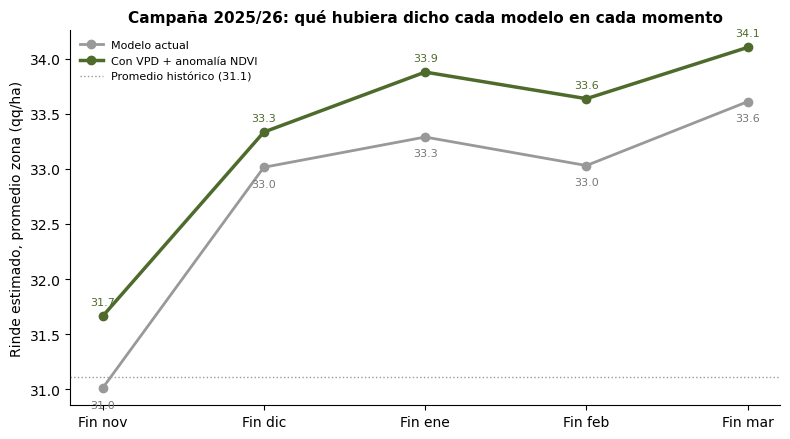

Guardado: outputs/comparacion_modelos_2526.png y .csv


In [20]:
c25 = df_clima_25.copy()
c25["mes_camp"] = c25["fecha"].apply(lambda f: mes_campana(f, CAMPANA_PRUEBA))
c25["vpd"] = (presion_vapor(c25["T2M_MAX"]) + presion_vapor(c25["T2M_MIN"])) / 2 - presion_vapor(c25["T2MDEW"])
n25 = df_ndvi_25.copy()
n25["mes_camp"] = n25["fecha"].apply(lambda f: mes_campana(f, CAMPANA_PRUEBA))
n25["doy"] = n25["fecha"].dt.dayofyear
n25 = n25.merge(clim, on=["partido", "doy"], how="left")       # "normal" 2000-2015 de la parte 1
n25["ndvi_anom"] = n25["ndvi"] - n25["ndvi_normal"]
 
filas = []
for partido in PARTIDOS:
    row = {"partido": partido}
    dc_p = c25[c25["partido"] == partido]
    dn_p = n25[n25["partido"] == partido].sort_values("fecha")
    for v, (m_ini, m_fin) in VENTANAS.items():
        dv = dc_p[(dc_p["mes_camp"] >= m_ini) & (dc_p["mes_camp"] <= m_fin)]
        nv = dn_p[(dn_p["mes_camp"] >= m_ini) & (dn_p["mes_camp"] <= m_fin)]
        # Mismas variables que el notebook 03
        row[f"precip_acum_{v}"] = dv["PRECTOTCORR"].sum()
        row[f"temp_media_{v}"] = dv["T2M"].mean()
        row[f"temp_max_media_{v}"] = dv["T2M_MAX"].mean()
        row[f"temp_min_media_{v}"] = dv["T2M_MIN"].mean()
        row[f"rad_media_{v}"] = dv["ALLSKY_SFC_SW_DWN"].mean()
        row[f"humedad_media_{v}"] = dv["RH2M"].mean()
        row[f"dias_calor_extremo_{v}"] = (dv["T2M_MAX"] > 35).sum()
        row[f"dias_sin_lluvia_{v}"] = (dv["PRECTOTCORR"] < 1).sum()
        row[f"ndvi_mean_{v}"] = nv["ndvi"].mean()
        row[f"ndvi_max_{v}"] = nv["ndvi"].max()
        row[f"ndvi_min_{v}"] = nv["ndvi"].min()
        row[f"ndvi_std_{v}"] = nv["ndvi"].std()
        row[f"ndvi_slope_{v}"] = np.polyfit(np.arange(len(nv)), nv["ndvi"].values, 1)[0] if len(nv) >= 2 else np.nan
        # Variables nuevas
        row[f"vpd_media_{v}"] = dv["vpd"].mean()
        row[f"ndvi_anom_media_{v}"] = nv["ndvi_anom"].mean()
        row[f"ndvi_anom_ultimo_{v}"] = nv["ndvi_anom"].dropna().iloc[-1] if nv["ndvi_anom"].notna().any() else np.nan
    filas.append(row)
df_25 = pd.DataFrame(filas)
 
def estimar(features):
    sc = StandardScaler().fit(df[features])
    preds = [RandomForestRegressor(**RF_PARAMS, random_state=s)
             .fit(sc.transform(df[features]), df["rinde_qq_ha"]).predict(sc.transform(df_25[features]))
             for s in SEMILLAS]
    return np.mean(preds, axis=0)
 
est = []
for v in NOMBRES_V:
    f_act = features_base(v)
    f_new = f_act + features_grupo(GRUPOS["VPD"] + GRUPOS["Anomalía NDVI"], v)
    faltan = df_25[f_new].columns[df_25[f_new].isna().any()].tolist()
    if faltan:
        print(f"{v}: faltan datos en {faltan[:3]}... se saltea")
        continue
    est.append(pd.DataFrame({"ventana": v, "partido": df_25["partido"],
                             "actual": estimar(f_act), "nuevo": estimar(f_new)}))
est = pd.concat(est, ignore_index=True)
 
media_hist = df.groupby("partido")["rinde_qq_ha"].mean()
etiq = {"oct_nov": "Fin nov", "oct_dic": "Fin dic", "oct_ene": "Fin ene", "oct_feb": "Fin feb", "oct_mar": "Fin mar"}
zona = est.groupby("ventana", sort=False)[["actual", "nuevo"]].mean()
prom_zona = media_hist.mean()
 
print(f"CAMPAÑA 2025/26 — promedio de la zona (qq/ha) · promedio histórico 2000-2024: {prom_zona:.1f}")
print("=" * 82)
print(f"{'Corte':9s}| {'Modelo actual':>13s} | {'vs hist.':>8s} | {'VPD + anomalía':>14s} | {'vs hist.':>8s} | {'Diferencia':>10s}")
print("-" * 82)
for v, r in zona.iterrows():
    print(f"{etiq[v]:9s}| {r.actual:13.1f} | {(r.actual/prom_zona-1):+8.1%} | {r.nuevo:14.1f} | {(r.nuevo/prom_zona-1):+8.1%} | {r.nuevo - r.actual:+10.1f}")
 
print("\nPor partido (qq/ha) — actual / con VPD + anomalía")
tab = est.assign(celda=lambda d: d["actual"].round(1).astype(str) + " / " + d["nuevo"].round(1).astype(str))
tab = tab.pivot(index="partido", columns="ventana", values="celda")[[v for v in NOMBRES_V if v in zona.index]]
tab.columns = [etiq[v] for v in tab.columns]
tab.insert(0, "Prom. hist.", media_hist.round(1))
print(tab.to_string())
 
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(zona))
ax.plot(x, zona["actual"], "o-", color="#999999", lw=2, label="Modelo actual")
ax.plot(x, zona["nuevo"], "o-", color="#4E6B2C", lw=2.5, label="Con VPD + anomalía NDVI")
for xi, (a, n) in enumerate(zip(zona["actual"], zona["nuevo"])):
    ax.annotate(f"{a:.1f}", (xi, a), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color="#777")
    ax.annotate(f"{n:.1f}", (xi, n), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, color="#4E6B2C")
ax.axhline(prom_zona, color="#999", ls=":", lw=1, label=f"Promedio histórico ({prom_zona:.1f})")
ax.set_xticks(x); ax.set_xticklabels([etiq[v] for v in zona.index])
ax.set_ylabel("Rinde estimado, promedio zona (qq/ha)")
ax.set_title("Campaña 2025/26: qué hubiera dicho cada modelo en cada momento", fontsize=11, fontweight="bold")
ax.legend(fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUTPUTS / "comparacion_modelos_2526.png", dpi=150, bbox_inches="tight")
plt.show()
est.round(2).to_csv(OUTPUTS / "comparacion_modelos_2526.csv", index=False)
print("Guardado: outputs/comparacion_modelos_2526.png y .csv")

# PARTE 4: ¿acertó cada modelo a CÓMO VENÍA cada campaña? (2016-2024 vs MAGyP)
# Usa las predicciones walk-forward ya calculadas en la parte 1 y 2: cada campaña
# se estimó sin haberla visto. No reentrena nada.


FIN NOV — promedio de la zona, desvío vs promedio histórico
Campaña |           Real (MAGyP) |          Modelo actual |       Con VPD + anomalía
------------------------------------------------------------------------------------------------
2016/17 | +13.4% muy arriba    |     +3.5% normal     ✔ |       +3.8% normal     ✔
2017/18 | -10.0% muy abajo     |     +3.0% normal     ✗ |       -0.7% normal     ✔
2018/19 |  +6.8% arriba        |     +3.4% normal     ✔ |       +3.7% normal     ✔
2019/20 |  +4.4% normal        |     +2.6% normal     ✔ |       +2.1% normal     ✔
2020/21 |  -7.8% abajo         |     +0.3% normal     ✗ |       +1.4% normal     ✗
2021/22 |  -6.8% abajo         |    -13.5% muy abajo  ✔ |       -7.0% abajo      ✔
2022/23 | -48.8% muy abajo     |    -31.8% muy abajo  ✔ |      -43.2% muy abajo  ✔
2023/24 |  -0.2% normal        |     +5.6% arriba     ✗ |       +7.2% arriba     ✗
2024/25 |  +1.5% normal        |    -21.2% muy abajo  ✗ |       -5.5% abajo      ✗
✔ / ✗ = ac

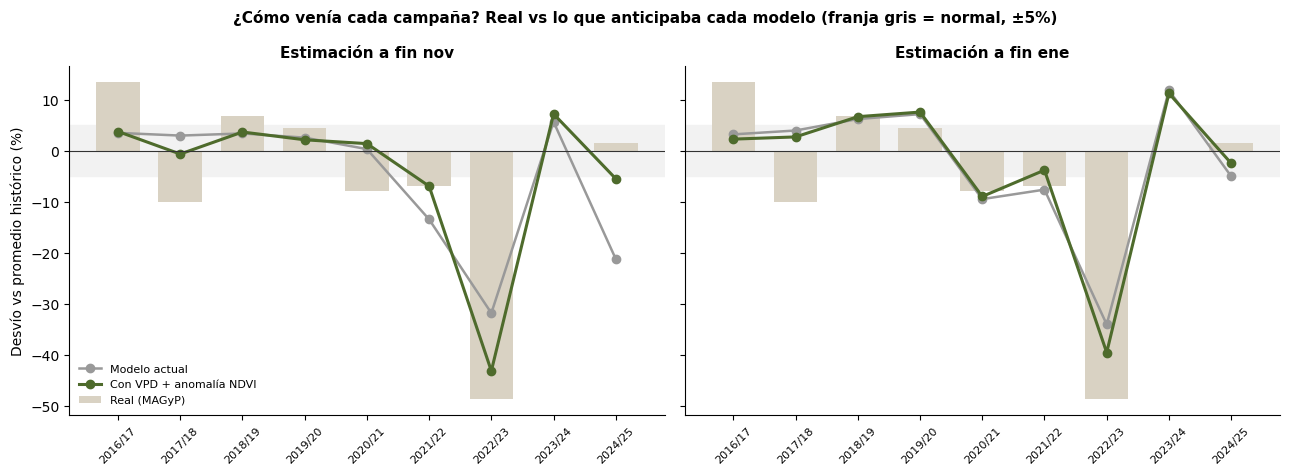

Guardado: outputs/direccion_campanas_2016_2024.png y .csv


In [21]:
def categoria(desvio):
    """Desvío porcentual respecto del promedio histórico -> cómo viene la campaña."""
    if desvio <= -10: return "muy abajo"
    if desvio <= -5:  return "abajo"
    if desvio < 5:    return "normal"
    if desvio < 10:   return "arriba"
    return "muy arriba"
 
MODELOS_CMP = {"Actual": "Modelo actual", "Nuevo": "+ VPD + Anomalía NDVI"}
etiq = {"oct_nov": "Fin nov", "oct_dic": "Fin dic", "oct_ene": "Fin ene", "oct_feb": "Fin feb", "oct_mar": "Fin mar"}
 
zonas = {}
for v in NOMBRES_V:
    base = resultados[("Modelo actual", v)][0]
    z = base.groupby("campana").agg(real=("real", "mean"), hist=("media_hist", "mean"))
    for corto, largo in MODELOS_CMP.items():
        z[corto] = resultados[(largo, v)][0].groupby("campana")["pred"].mean()
    for col in ["real"] + list(MODELOS_CMP):
        z[f"{col}_%"] = (z[col] / z["hist"] - 1) * 100
        z[f"{col}_cat"] = z[f"{col}_%"].map(categoria)
    zonas[v] = z
 
# --- Detalle por campaña en los dos cortes clave
for v in ["oct_nov", "oct_ene"]:
    z = zonas[v]
    print(f"\n{etiq[v].upper()} — promedio de la zona, desvío vs promedio histórico")
    print("=" * 96)
    print(f"{'Campaña':8s}| {'Real (MAGyP)':>22s} | {'Modelo actual':>22s} | {'Con VPD + anomalía':>24s}")
    print("-" * 96)
    for c, r in z.iterrows():
        def celda(m):
            dir_ok = np.sign(r[f"{m}_%"]) == np.sign(r["real_%"])
            return f"{r[f'{m}_%']:+5.1f}% {r[f'{m}_cat']:10s} {'✔' if dir_ok else '✗'}"
        print(f"{c}/{str(c+1)[2:]} | {r['real_%']:+5.1f}% {r['real_cat']:13s} | {celda('Actual'):>22s} | {celda('Nuevo'):>24s}")
    print("✔ / ✗ = acertó o no si la campaña venía arriba o abajo del promedio.")
 
# --- Resumen por corte
print("\n\nRESUMEN 2016-2024 (9 campañas)")
print("=" * 96)
print(f"{'Corte':9s}| {'Dirección zona':^19s} | {'Dirección partidos':^21s} | {'Categoría exacta':^19s} | {'Detecta años malos':^19s}")
print(f"{'':9s}| {'Actual':>8s} {'Nuevo':>9s} | {'Actual':>9s} {'Nuevo':>10s} | {'Actual':>8s} {'Nuevo':>9s} | {'Actual':>8s} {'Nuevo':>9s}")
print("-" * 96)
for v in NOMBRES_V:
    z = zonas[v]
    malos = z[z["real_%"] <= -5]
    fila = f"{etiq[v]:9s}|"
    dz = [(np.sign(z[f"{m}_%"]) == np.sign(z["real_%"])).sum() for m in MODELOS_CMP]
    dp = []
    for largo in MODELOS_CMP.values():
        r = resultados[(largo, v)][0]
        dp.append((np.sign(r["pred"] - r["media_hist"]) == np.sign(r["real"] - r["media_hist"])).mean())
    cat = [(z[f"{m}_cat"] == z["real_cat"]).sum() for m in MODELOS_CMP]
    det = [(malos[f"{m}_%"] < 0).sum() for m in MODELOS_CMP]
    fila += f" {dz[0]:>5d}/9 {dz[1]:>6d}/9 | {dp[0]:>9.0%} {dp[1]:>10.0%} | {cat[0]:>5d}/9 {cat[1]:>6d}/9 | {det[0]:>5d}/{len(malos)} {det[1]:>6d}/{len(malos)}"
    print(fila)
print("""
Dirección zona:      campañas en que acertó si la zona venía arriba o abajo del promedio.
Dirección partidos:  lo mismo, partido por partido (45 casos).
Categoría exacta:    acertó la categoría (muy abajo / abajo / normal / arriba / muy arriba, cortes en ±5% y ±10%).
Detecta años malos:  de las campañas que terminaron 5% o más abajo del promedio, en cuántas el modelo ya marcaba "abajo".""")
 
# --- Gráfico: desvío real vs estimado por campaña, en los dos cortes clave
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, v in zip(axes, ["oct_nov", "oct_ene"]):
    z = zonas[v]
    x = np.arange(len(z))
    ax.bar(x, z["real_%"], color="#D9D2C3", width=0.7, label="Real (MAGyP)")
    ax.plot(x, z["Actual_%"], "o-", color="#999999", lw=1.8, label="Modelo actual")
    ax.plot(x, z["Nuevo_%"], "o-", color="#4E6B2C", lw=2.2, label="Con VPD + anomalía NDVI")
    ax.axhspan(-5, 5, color="#f2f2f2", zorder=0)
    ax.axhline(0, color="#333", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels([f"{c}/{str(c+1)[2:]}" for c in z.index], rotation=45, fontsize=8)
    ax.set_title(f"Estimación a {etiq[v].lower()}", fontsize=11, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Desvío vs promedio histórico (%)")
axes[0].legend(fontsize=8, frameon=False, loc="lower left")
fig.suptitle("¿Cómo venía cada campaña? Real vs lo que anticipaba cada modelo (franja gris = normal, ±5%)",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUTS / "direccion_campanas_2016_2024.png", dpi=150, bbox_inches="tight")
plt.show()
 
pd.concat({etiq[v]: zonas[v] for v in NOMBRES_V}, names=["corte"]).round(2).to_csv(OUTPUTS / "direccion_campanas_2016_2024.csv")
print("Guardado: outputs/direccion_campanas_2016_2024.png y .csv")